# Exploratory Data Analysis
**Purpose:** Understand the merged Delhi data before cleaning anything.

**Input:** `data/cleaned/delhi_merged.csv`

**Output:** none (findings are written at the end)

## 1. Setup and load data


In [2]:
from pathlib import Path
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

BASE = Path.cwd().parent
df = pd.read_csv(BASE / "data" / "cleaned" / "delhi_merged.csv", parse_dates=["Date"])
df = df.set_index("Date")
print(df.shape)
df.info()

(2009, 19)
<class 'pandas.DataFrame'>
DatetimeIndex: 2009 entries, 2015-01-01 to 2020-07-01
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   City                         2009 non-null   str    
 1   PM2.5                        2007 non-null   float64
 2   PM10                         1932 non-null   float64
 3   NO                           2007 non-null   float64
 4   NO2                          2007 non-null   float64
 5   NOx                          2009 non-null   float64
 6   NH3                          2000 non-null   float64
 7   CO                           2009 non-null   float64
 8   SO2                          1899 non-null   float64
 9   O3                           1925 non-null   float64
 10  Benzene                      2009 non-null   float64
 11  Toluene                      2009 non-null   float64
 12  Xylene                       1228 non-null   float64
 13  

## 2. Missing values and summary statistics


In [3]:
print((df.isna().mean() * 100).round(1).sort_values(ascending=False))
df.describe().T

Xylene                         38.9
SO2                             5.5
O3                              4.2
PM10                            3.8
AQI                             0.5
AQI_Bucket                      0.5
NH3                             0.4
NO2                             0.1
PM2.5                           0.1
NO                              0.1
City                            0.0
Benzene                         0.0
CO                              0.0
NOx                             0.0
Toluene                         0.0
temperature_2m_mean             0.0
precipitation_sum               0.0
wind_speed_10m_max              0.0
wind_direction_10m_dominant     0.0
dtype: float64


,count,mean,std,min,25%,50%,75%,max
PM2.5,2007.0,117.196153,82.912945,10.24,57.0950,94.62,153.0300,685.36
PM10,1932.0,232.809229,121.873025,18.59,137.0400,216.73,311.6675,796.88
NO,2007.0,38.985595,33.389456,3.57,15.8950,27.20,50.7900,221.03
NO2,2007.0,50.785182,22.696721,10.63,33.8950,47.15,63.5700,162.50
NOx,2009.0,58.567023,37.690350,0.00,31.1500,52.75,75.3600,254.80
NH3,2000.0,41.997150,17.301221,6.78,31.1575,38.04,48.7925,166.70
CO,2009.0,1.976053,2.560253,0.00,0.9100,1.24,1.8700,30.44
SO2,1899.0,15.901253,7.966770,2.34,10.3350,14.45,19.7000,71.56
O3,1925.0,51.323610,26.062340,6.94,33.7100,44.44,60.8400,257.73
Benzene,2009.0,3.544480,2.431232,0.00,1.8700,2.96,4.6800,20.64


## 3. Distributions of pollutants
Nearly all pollutants are right-skewed, so a log transform will be needed later.


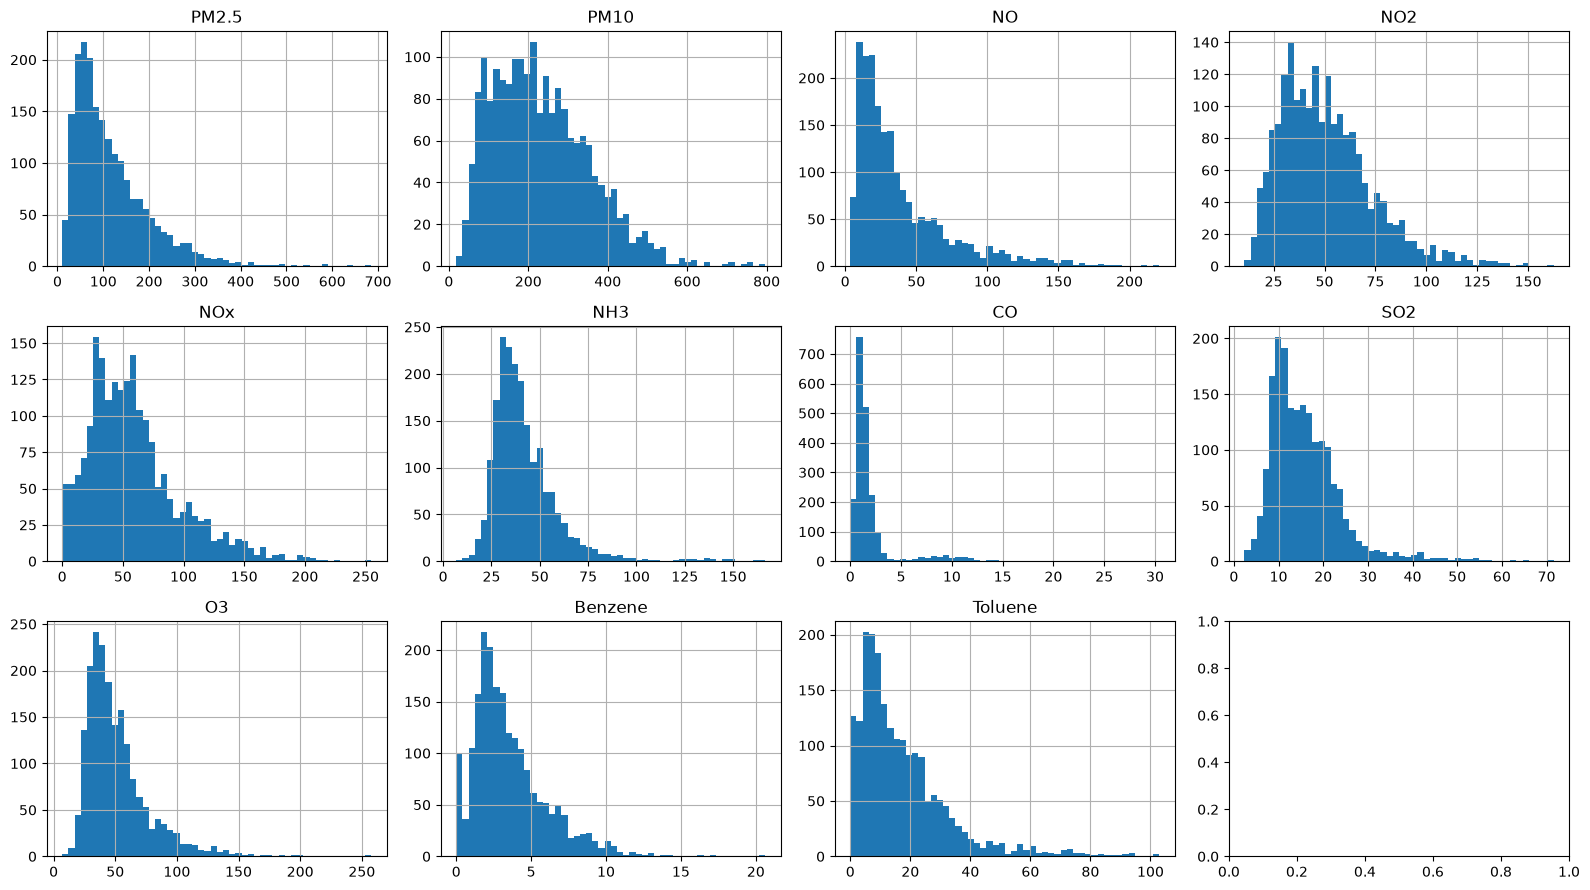

In [4]:
pollutants = ["PM2.5","PM10","NO","NO2","NOx","NH3","CO","SO2","O3","Benzene","Toluene"]
fig, axes = plt.subplots(3, 4, figsize=(16, 9))
for ax, col in zip(axes.ravel(), pollutants):
    df[col].hist(bins=50, ax=ax)
    ax.set_title(col)
plt.tight_layout(); plt.show()

## 4. Time series (PM2.5, NO2, O3)
Look for seasonal cycles, gaps, and level changes.

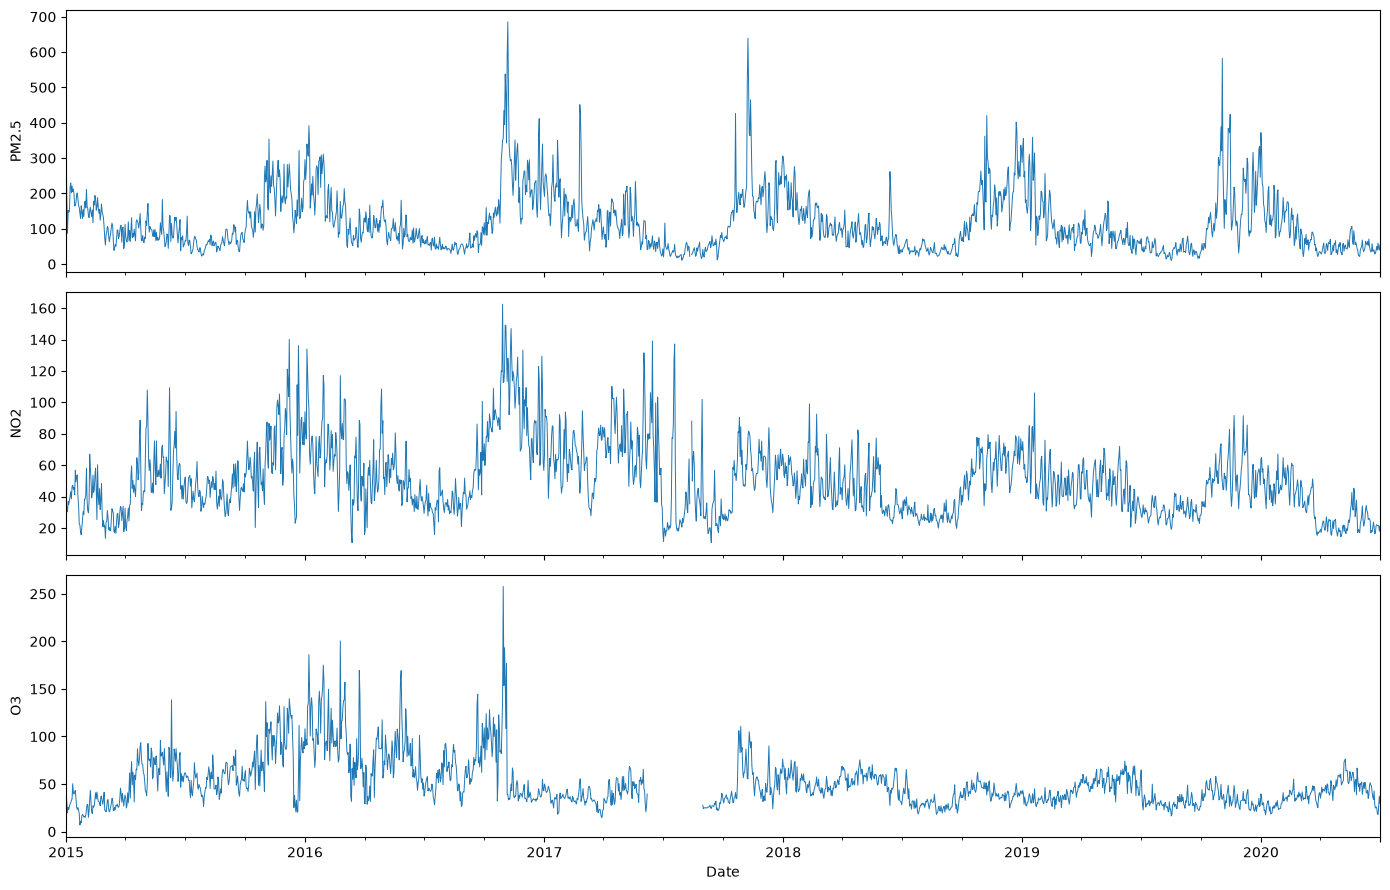

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
for ax, col in zip(axes, ["PM2.5", "NO2", "O3"]):
    df[col].plot(ax=ax, linewidth=0.7)
    ax.set_ylabel(col)
plt.tight_layout(); plt.show()

## 5. Seasonality by month

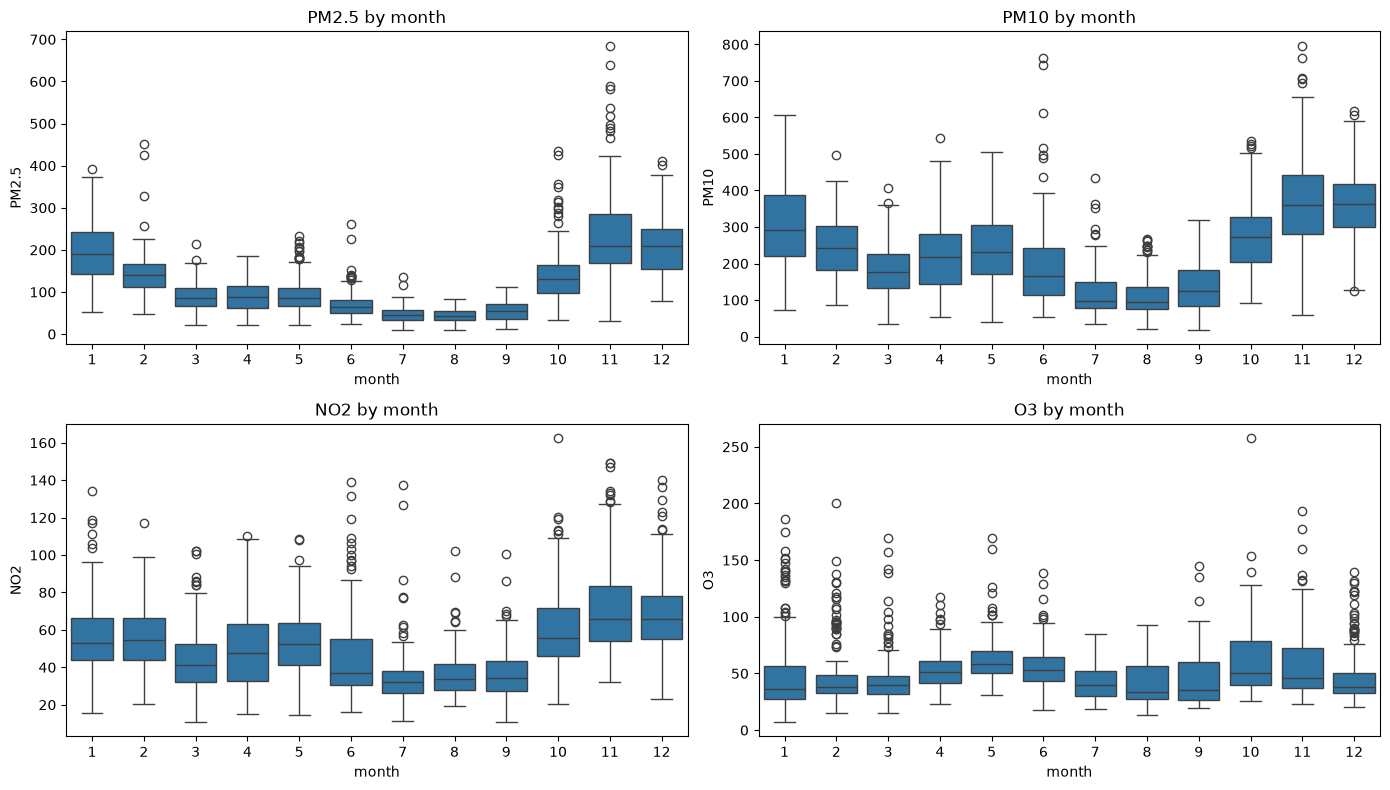

In [6]:
df["month"] = df.index.month
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, col in zip(axes.ravel(), ["PM2.5", "PM10", "NO2", "O3"]):
    sns.boxplot(data=df, x="month", y=col, ax=ax)
    ax.set_title(f"{col} by month")
plt.tight_layout(); plt.show()

## 6. Correlation between pollutants and weather

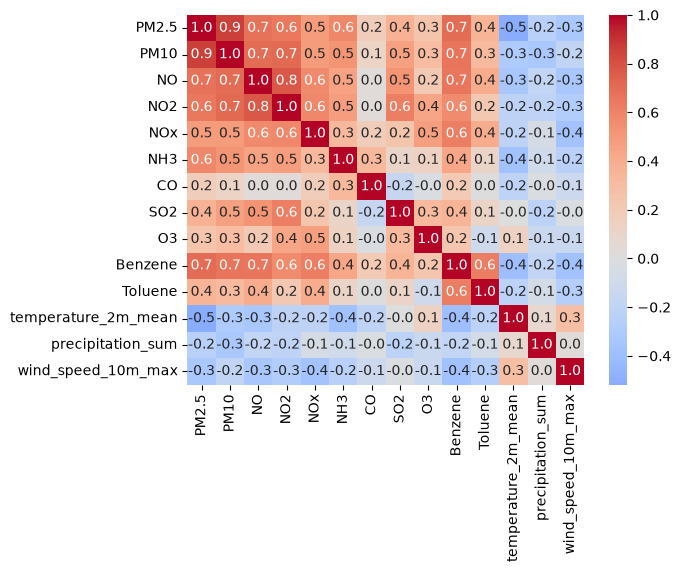

In [7]:
weather_cols = ["temperature_2m_mean", "precipitation_sum", "wind_speed_10m_max"]
sns.heatmap(df[pollutants + weather_cols].corr(), annot=True, fmt=".1f", cmap="coolwarm", center=0)
plt.show()

## 7. Weekday effect and yearly averages


In [8]:
print(df.groupby(df.index.dayofweek)[["PM2.5", "NO2"]].mean().round(1))
print(df.groupby(df.index.year)[["PM2.5", "PM10", "NO2"]].mean().round(1))

      PM2.5   NO2
Date             
0     114.6  50.5
1     115.8  52.0
2     117.3  52.5
3     120.3  51.9
4     118.9  50.9
5     117.2  49.8
6     116.3  47.9
      PM2.5   PM10   NO2
Date                    
2015  117.3  230.0  50.4
2016  138.5  258.3  63.5
2017  125.1  264.4  57.7
2018  115.0  240.1  45.9
2019  108.5  215.0  45.2
2020   80.3  157.0  33.2


## Key findings
- PM2.5, PM10 and NO2 peak October to January and are lowest in July to August (monsoon).
- PM10 stays high in April to June while PM2.5 is low, which suggests dust.
- PM2.5 correlates with low temperature (-0.5) and low wind speed (-0.3).
- Almost no weekday effect.
- Yearly means are not directly comparable: 2020 covers January to July only.
- O3, NO2 and CO levels shift in late 2016 (investigated in notebook 03).